# FinSignal · 03 Model Selection, Testing and Experimental Results
**ISOM5240 Group 7** · Company: **Wealthsimple** (https://www.wealthsimple.com/)

This notebook covers the two experiment objectives required by the project:

| Experiment | Metric(s) | Section |
|---|---|---|
| (i) **Model selection** for each pipeline | accuracy **and** runtime | 4 – 6 |
| (ii) **Application performance** of the final two-pipeline app | accuracy | 7 – 9 |
| Label-quality check (blind human spot-check of event labels) | agreement, Cohen's kappa | 7b |

All candidates are evaluated on the **same held-out test samples** (never used for fine-tuning).
Results are written to **`Experimental_results.xlsx`**.



## 1. Setup

In [1]:
# library versions (identical to the deployed Streamlit app's requirements.txt)
!pip -q install "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.10.1" "huggingface_hub>=0.34,<1.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 28.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompa

In [2]:
import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import transformers
from transformers import pipeline, set_seed
from huggingface_hub import hf_hub_download

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
GPU = 0 if torch.cuda.is_available() else -1
DEVICE_NAME = torch.cuda.get_device_name(0) if GPU == 0 else "CPU"
print("transformers", transformers.__version__, "| device:", DEVICE_NAME)

transformers 4.57.1 | device: Tesla T4


In [3]:
HF_USERNAME = "Ikenna14"   # <- same account used in notebooks 01 and 02
SENT_MODEL  = f"{HF_USERNAME}/finsignal-sentiment-distilbert"
EVENT_MODEL = f"{HF_USERNAME}/finsignal-event-distilbert"
MAX_LEN = 96
SELECTION_N = 1000     # stratified test subset per pipeline used for model selection
APP_TEST_N = 500       # labelled samples per pipeline bundled with the Streamlit app
CPU_TIMING_N = 200     # samples used to estimate CPU (Streamlit Cloud) runtime
GITHUB_REPO = "Ikenna1414/ISOM_5240_Sentiment_Analysis_Project"
SPOTCHECK_FILE = "event_mapping_spotcheck.xlsx"   # blind manual labels (data/ folder of the repo)
os.makedirs("data", exist_ok=True)

## 2. Rebuild the held-out test sets (identical pre-processing to notebooks 01 / 02)

In [4]:
import html, re

_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_WS_RE = re.compile(r"\s+")

def clean_text(text):
    """Unescape HTML entities (&amp; -> &), remove URLs, normalise whitespace.
    The exact same function is used in the Streamlit app (utils.py)."""
    if text is None:
        return ""
    text = html.unescape(str(text))
    text = _URL_RE.sub(" ", text)
    return _WS_RE.sub(" ", text).strip()

print(clean_text("Fed hikes rates by 25bp &amp; signals pause https://t.co/abc123  "))

Fed hikes rates by 25bp & signals pause


In [5]:
# Dataset card: LABEL_0 = Bearish, LABEL_1 = Bullish, LABEL_2 = Neutral
SENT_LABELS = ["Bearish", "Bullish", "Neutral"]
SENT_ID2LABEL = dict(enumerate(SENT_LABELS))
SENT_LABEL2ID = {v: k for k, v in SENT_ID2LABEL.items()}
SENT_ID2LABEL

{0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}

In [6]:
# Original 20 topic labels of zeroshot/twitter-financial-news-topic (from the dataset card)
TOPIC_NAMES = {
    0: "Analyst Update", 1: "Fed | Central Banks", 2: "Company | Product News",
    3: "Treasuries | Corporate Debt", 4: "Dividend", 5: "Earnings", 6: "Energy | Oil",
    7: "Financials", 8: "Currencies", 9: "General News | Opinion",
    10: "Gold | Metals | Materials", 11: "IPO", 12: "Legal | Regulation",
    13: "M&A | Investments", 14: "Macro", 15: "Markets", 16: "Politics",
    17: "Personnel Change", 18: "Stock Commentary", 19: "Stock Movement",
}

# Project event taxonomy = the 7 corporate event categories in the approved proposal
EVENT_LABELS = ["Earnings & Guidance", "Mergers & Acquisitions", "Regulatory & Legal", "Financing",
                "Management Change", "Product & Business Expansion", "Other"]

# Rule: map a source topic to an event only when the topic is company-specific and matches the
# event definition; everything else (macro, markets, commentary, analyst calls, dividends) -> Other.
TOPIC_TO_EVENT = {
    5: "Earnings & Guidance",
    13: "Mergers & Acquisitions",
    12: "Regulatory & Legal",
    3: "Financing", 11: "Financing",          # corporate debt, IPOs
    17: "Management Change",
    2: "Product & Business Expansion",
    0: "Other", 1: "Other", 4: "Other", 6: "Other", 7: "Other", 8: "Other", 9: "Other",
    10: "Other", 14: "Other", 15: "Other", 16: "Other", 18: "Other", 19: "Other",
}
assert set(TOPIC_TO_EVENT) == set(range(20)) and set(TOPIC_TO_EVENT.values()) == set(EVENT_LABELS)

EVENT_ID2LABEL = dict(enumerate(EVENT_LABELS))
EVENT_LABEL2ID = {v: k for k, v in EVENT_ID2LABEL.items()}
pd.DataFrame({"original_topic": TOPIC_NAMES.values(),
              "project_event": [TOPIC_TO_EVENT[i] for i in TOPIC_NAMES]})

,original_topic,project_event
0,Analyst Update,Other
1,Fed | Central Banks,Other
2,Company | Product News,Product & Business Expansion
3,Treasuries | Corporate Debt,Financing
4,Dividend,Other
5,Earnings,Earnings & Guidance
6,Energy | Oil,Other
7,Financials,Other
8,Currencies,Other
9,General News | Opinion,Other


In [7]:
def prepare(df, label_fn):
    out = pd.DataFrame({"text": df["text"].map(clean_text), "label_name": df["label"].map(label_fn)})
    out = out[out["text"].str.len() > 0]
    return out.drop_duplicates(subset="text").reset_index(drop=True)

sent_test = prepare(load_dataset("zeroshot/twitter-financial-news-sentiment")["validation"].to_pandas(),
                    lambda y: SENT_ID2LABEL[int(y)])
event_test = prepare(load_dataset("zeroshot/twitter-financial-news-topic")["validation"].to_pandas(),
                     lambda y: TOPIC_TO_EVENT[int(y)])
print("sentiment test:", len(sent_test), "| event test:", len(event_test))

def stratified_subset(df, n):
    sub, _ = train_test_split(df, train_size=n, stratify=df["label_name"], random_state=SEED)
    return sub.reset_index(drop=True)

sent_sel = stratified_subset(sent_test, SELECTION_N)
event_sel = stratified_subset(event_test, SELECTION_N)
pd.concat({"sentiment subset": sent_sel["label_name"].value_counts(),
           "event subset": event_sel["label_name"].value_counts()}, axis=1).fillna(0).astype(int)

README.md: 0.00B [00:00, ?B/s]

sent_train.csv: 0.00B [00:00, ?B/s]

sent_valid.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

...

topic_valid.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/16990 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4117 [00:00<?, ? examples/s]

sentiment test: 2377 | event test: 3972


,sentiment subset,event subset
label_name,,
Neutral,655,0
Bullish,200,0
Bearish,145,0
Other,0,622
Product & Business Expansion,0,209
Earnings & Guidance,0,61
Regulatory & Legal,0,29
Mergers & Acquisitions,0,29
Management Change,0,28


## 3. Evaluation helpers

In [8]:
def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def run_classifier(model_id, texts, label_map=None, device=GPU, batch_size=64):
    """Text-classification pipeline -> (predicted label names, seconds, ms/sample)."""
    clf = pipeline("text-classification", model=model_id, device=device)
    kw = dict(batch_size=batch_size, truncation=True, max_length=MAX_LEN)
    clf(texts[:16], **kw)                     # warm-up (excluded from timing)
    sync(); t0 = time.perf_counter()
    out = clf(texts, **kw)
    sync(); secs = time.perf_counter() - t0
    preds = [(label_map or {}).get(o["label"].lower(), o["label"]) for o in out]
    del clf; torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return preds, secs, secs / len(texts) * 1000

def run_zero_shot(model_id, texts, hypotheses, device=GPU, batch_size=32):
    """Zero-shot NLI pipeline (no fine-tuning) used as a baseline."""
    zs = pipeline("zero-shot-classification", model=model_id, device=device)
    cand = list(hypotheses.values()); back = {v: k for k, v in hypotheses.items()}
    kw = dict(candidate_labels=cand, hypothesis_template="This financial news is about {}.",
              batch_size=batch_size)
    zs(texts[:8], **kw)
    sync(); t0 = time.perf_counter()
    out = zs(texts, **kw)
    sync(); secs = time.perf_counter() - t0
    del zs; torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return [back[o["labels"][0]] for o in out], secs, secs / len(texts) * 1000

def score(name, kind, y_true, preds, secs, ms):
    return {"model": name, "type": kind, "samples": len(y_true),
            "accuracy": accuracy_score(y_true, preds),
            "macro_f1": f1_score(y_true, preds, average="macro"),
            "runtime_s": round(secs, 2), "ms_per_sample": round(ms, 2), "device": DEVICE_NAME}

## 4. Pipeline 1 (sentiment): model selection
| Candidate | Description |
|---|---|
| `ProsusAI/finbert` | BERT-base further pre-trained on financial text, fine-tuned on Financial PhraseBank (off-the-shelf) |
| `mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis` | DistilRoBERTa fine-tuned on Financial PhraseBank (off-the-shelf) |
| **`finsignal-sentiment-distilbert`** | DistilBERT fine-tuned by the team on financial news (notebook 01) |

Off-the-shelf models output positive / negative / neutral, mapped to Bullish / Bearish / Neutral.

In [9]:
POLARITY = {"positive": "Bullish", "negative": "Bearish", "neutral": "Neutral",
            "bullish": "Bullish", "bearish": "Bearish"}
p1_candidates = [
    ("ProsusAI/finbert", "pre-trained (off-the-shelf)"),
    ("mrm8488/distilroberta-finetuned-financial-news-sentiment-analysis", "pre-trained (off-the-shelf)"),
    (SENT_MODEL, "fine-tuned by team"),
]
texts, y_true = sent_sel["text"].tolist(), sent_sel["label_name"].tolist()
p1_rows, p1_preds = [], {}
for model_id, kind in p1_candidates:
    preds, secs, ms = run_classifier(model_id, texts, POLARITY)
    p1_preds[model_id] = preds
    p1_rows.append(score(model_id, kind, y_true, preds, secs, ms))
    print(f"{model_id:<70} acc={p1_rows[-1]['accuracy']:.4f}  {ms:.2f} ms/sample")
maj = pd.Series(y_true).mode()[0]
p1_rows.append(score(f"majority class ({maj})", "naive baseline", y_true, [maj] * len(y_true), 0.0, 0.0))
p1_sel = pd.DataFrame(p1_rows).sort_values(["accuracy", "ms_per_sample"], ascending=[False, True]).reset_index(drop=True)
p1_sel

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Device set to use cuda:0


Ikenna14/finsignal-sentiment-distilbert                                acc=0.8660  1.51 ms/sample


,model,type,samples,accuracy,macro_f1,runtime_s,ms_per_sample,device
0,Ikenna14/finsignal-sentiment-distilbert,fine-tuned by team,1000,0.866,0.828803,1.51,1.51,Tesla T4
1,mrm8488/distilroberta-finetuned-financial-news...,pre-trained (off-the-shelf),1000,0.772,0.730966,1.52,1.52,Tesla T4
2,ProsusAI/finbert,pre-trained (off-the-shelf),1000,0.723,0.666133,2.38,2.38,Tesla T4
3,majority class (Neutral),naive baseline,1000,0.655,0.263847,0.00,0.00,Tesla T4


## 5. Pipeline 2 (event type): model selection
No off-the-shelf model predicts our 7 event categories, so the baselines are **zero-shot NLI models**
(pre-trained on MNLI, no task-specific training) compared against our fine-tuned DistilBERT.

| Candidate | Description |
|---|---|
| `facebook/bart-large-mnli` | BART-large NLI, zero-shot (406M parameters) |
| `valhalla/distilbart-mnli-12-3` | distilled BART NLI, zero-shot (faster) |
| **`finsignal-event-distilbert`** | DistilBERT fine-tuned by the team (notebook 02, 66M parameters) |

In [10]:
ZS_HYPOTHESES = {
    "Earnings & Guidance": "company earnings results or financial guidance",
    "Mergers & Acquisitions": "a merger, acquisition or investment stake",
    "Regulatory & Legal": "a lawsuit, investigation or regulation",
    "Financing": "corporate debt, bonds or an IPO",
    "Management Change": "an executive or leadership change",
    "Product & Business Expansion": "a company's products, contracts or business expansion",
    "Other": "the overall stock market, economy, analyst ratings or politics",
}
texts, y_true = event_sel["text"].tolist(), event_sel["label_name"].tolist()
p2_rows, p2_preds = [], {}
for model_id in ["facebook/bart-large-mnli", "valhalla/distilbart-mnli-12-3"]:
    preds, secs, ms = run_zero_shot(model_id, texts, ZS_HYPOTHESES)
    p2_preds[model_id] = preds
    p2_rows.append(score(model_id, "pre-trained zero-shot", y_true, preds, secs, ms))
    print(f"{model_id:<45} acc={p2_rows[-1]['accuracy']:.4f}  {ms:.2f} ms/sample")
preds, secs, ms = run_classifier(EVENT_MODEL, texts)
p2_preds[EVENT_MODEL] = preds
p2_rows.append(score(EVENT_MODEL, "fine-tuned by team", y_true, preds, secs, ms))
print(f"{EVENT_MODEL:<45} acc={p2_rows[-1]['accuracy']:.4f}  {ms:.2f} ms/sample")
maj = pd.Series(y_true).mode()[0]
p2_rows.append(score(f"majority class ({maj})", "naive baseline", y_true, [maj] * len(y_true), 0.0, 0.0))
p2_sel = pd.DataFrame(p2_rows).sort_values(["accuracy", "ms_per_sample"], ascending=[False, True]).reset_index(drop=True)
p2_sel

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Device set to use cuda:0


Ikenna14/finsignal-event-distilbert           acc=0.9290  2.24 ms/sample


,model,type,samples,accuracy,macro_f1,runtime_s,ms_per_sample,device
0,Ikenna14/finsignal-event-distilbert,fine-tuned by team,1000,0.929,0.887541,2.24,2.24,Tesla T4
1,majority class (Other),naive baseline,1000,0.622,0.109565,0.00,0.00,Tesla T4
2,facebook/bart-large-mnli,pre-trained zero-shot,1000,0.331,0.377616,102.91,102.91,Tesla T4
3,valhalla/distilbart-mnli-12-3,pre-trained zero-shot,1000,0.293,0.372624,64.79,64.79,Tesla T4


## 6. Selection decision (highest accuracy; runtime breaks ties)

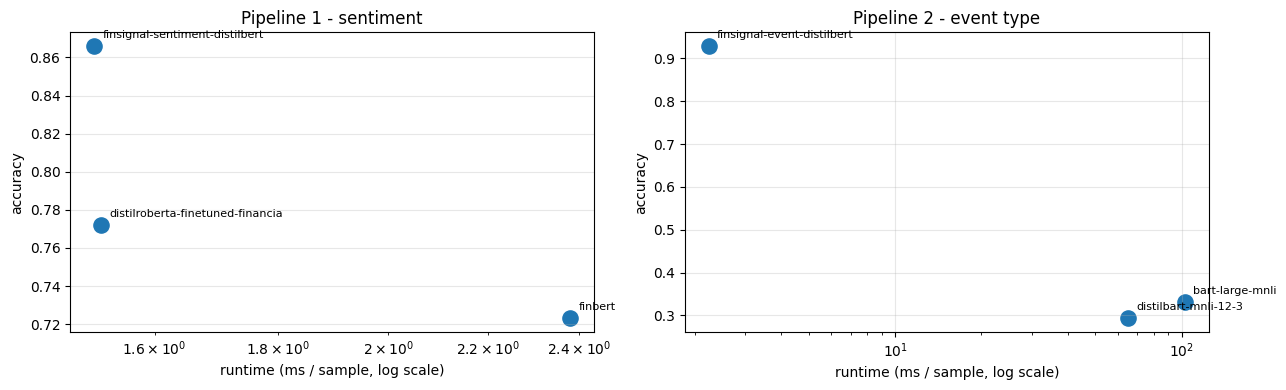

Selected Pipeline 1 model: Ikenna14/finsignal-sentiment-distilbert
Selected Pipeline 2 model: Ikenna14/finsignal-event-distilbert


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, df, title in [(axes[0], p1_sel, "Pipeline 1 - sentiment"), (axes[1], p2_sel, "Pipeline 2 - event type")]:
    df = df[df["type"] != "naive baseline"]
    short = [m.split("/")[-1][:32] for m in df["model"]]
    ax.scatter(df["ms_per_sample"], df["accuracy"], s=120)
    for x, y, s in zip(df["ms_per_sample"], df["accuracy"], short):
        ax.annotate(s, (x, y), textcoords="offset points", xytext=(6, 6), fontsize=8)
    ax.set_xlabel("runtime (ms / sample, log scale)"); ax.set_ylabel("accuracy"); ax.set_xscale("log")
    ax.set_title(title); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

best_p1 = p1_sel[p1_sel["type"] != "naive baseline"].iloc[0]["model"]
best_p2 = p2_sel[p2_sel["type"] != "naive baseline"].iloc[0]["model"]
print("Selected Pipeline 1 model:", best_p1)
print("Selected Pipeline 2 model:", best_p2)
for best, ours in [(best_p1, SENT_MODEL), (best_p2, EVENT_MODEL)]:
    if best != ours:
        print(f"NOTE: {best} beat {ours}. Update the model ID in the app (utils.py) and section 7 so the "
              "deployed model matches the selected one.")

## 7. Final models on the FULL held-out test sets

In [12]:
final_rows, reports, cms, errors = [], {}, {}, []
for name, model_id, test, labels in [("Pipeline 1 - sentiment", SENT_MODEL, sent_test, SENT_LABELS),
                                     ("Pipeline 2 - event type", EVENT_MODEL, event_test, EVENT_LABELS)]:
    preds, secs, ms = run_classifier(model_id, test["text"].tolist())
    y = test["label_name"].tolist()
    row = score(model_id, name, y, preds, secs, ms); row["pipeline"] = name
    final_rows.append(row)
    reports[name] = pd.DataFrame(classification_report(y, preds, labels=labels, output_dict=True, digits=4)).T
    cms[name] = pd.DataFrame(confusion_matrix(y, preds, labels=labels), index=labels, columns=labels)
    err = test.assign(predicted=preds)
    err = err[err["label_name"] != err["predicted"]].head(25).assign(pipeline=name)
    errors.append(err[["pipeline", "text", "label_name", "predicted"]])
    print(f"{name}: accuracy={row['accuracy']:.4f} macro-F1={row['macro_f1']:.4f} on {len(y)} samples")
    print(classification_report(y, preds, labels=labels, digits=4))
final_df = pd.DataFrame(final_rows)[["pipeline", "model", "samples", "accuracy", "macro_f1", "runtime_s", "ms_per_sample", "device"]]
final_df

Device set to use cuda:0


Pipeline 1 - sentiment: accuracy=0.8734 macro-F1=0.8350 on 2377 samples
              precision    recall  f1-score   support

     Bearish     0.7534    0.8058    0.7787       345
     Bullish     0.8215    0.8042    0.8128       475
     Neutral     0.9177    0.9094    0.9135      1557

    accuracy                         0.8734      2377
   macro avg     0.8309    0.8398    0.8350      2377
weighted avg     0.8746    0.8734    0.8738      2377



Device set to use cuda:0


Pipeline 2 - event type: accuracy=0.9338 macro-F1=0.8924 on 3972 samples
                              precision    recall  f1-score   support

         Earnings & Guidance     0.9438    0.9711    0.9572       242
      Mergers & Acquisitions     0.8829    0.8448    0.8634       116
          Regulatory & Legal     0.8482    0.8261    0.8370       115
                   Financing     0.8608    0.7907    0.8242        86
           Management Change     0.9346    0.9009    0.9174       111
Product & Business Expansion     0.8788    0.8989    0.8888       831
                       Other     0.9602    0.9575    0.9589      2471

                    accuracy                         0.9338      3972
                   macro avg     0.9013    0.8843    0.8924      3972
                weighted avg     0.9338    0.9338    0.9337      3972



,pipeline,model,samples,accuracy,macro_f1,runtime_s,ms_per_sample,device
0,Pipeline 1 - sentiment,Ikenna14/finsignal-sentiment-distilbert,2377,0.873370,0.835009,2.91,1.22,Tesla T4
1,Pipeline 2 - event type,Ikenna14/finsignal-event-distilbert,3972,0.933787,0.892424,7.40,1.86,Tesla T4


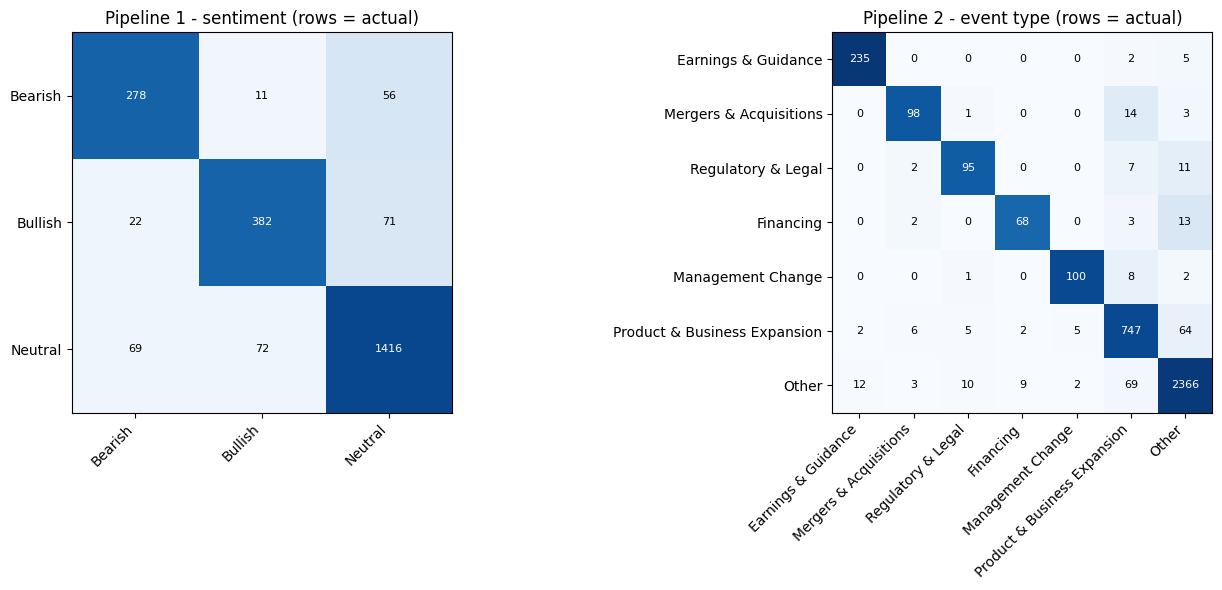

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2]})
for ax, (name, cm) in zip(axes, cms.items()):
    norm = cm.div(cm.sum(axis=1), axis=0)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index)
    for i in range(len(cm)):
        for j in range(len(cm)):
            ax.text(j, i, cm.iloc[i, j], ha="center", va="center",
                    color="white" if norm.iloc[i, j] > .5 else "black", fontsize=8)
    ax.set_title(f"{name} (rows = actual)")
plt.tight_layout(); plt.show()

## 7b. Label-quality check: blind manual spot-check of the topic -> event mapping
The event labels come from mapping the dataset's 20 annotated topics to the proposal's 7 categories.
To measure how faithful that mapping is, team members labelled a **stratified random sample of 150
held-out test headlines blind** (without seeing the topic or mapped label), using the category guide in
`data/event_mapping_spotcheck.xlsx`. We report:
- **mapping agreement**: share of headlines where the automatic label equals the human label (+ Cohen's kappa)
- **fine-tuned model vs human labels**: accuracy of the deployed event model against the human labels

In [14]:
def load_spotcheck():
    local = os.path.join("data", SPOTCHECK_FILE)
    src = local if os.path.exists(local) else f"https://raw.githubusercontent.com/{GITHUB_REPO}/main/data/{SPOTCHECK_FILE}"
    try:
        lab = pd.read_excel(src, sheet_name="Label")
        key = pd.read_excel(src, sheet_name="_key")
    except Exception as e:
        print("Spot-check file not available:", e); return None
    df = lab.merge(key, on="item_id")
    df = df[df["manual_event"].isin(EVENT_LABELS)].reset_index(drop=True)
    print(f"Loaded {len(df)} manually labelled headlines from {src}")
    return df if len(df) >= 30 else None

spot = load_spotcheck()
spot_summary = pd.DataFrame()
spot_class = pd.DataFrame()
if spot is not None:
    from sklearn.metrics import cohen_kappa_score
    spot["model_event"], _, _ = run_classifier(EVENT_MODEL, [clean_text(t) for t in spot["headline"]])
    spot_summary = pd.DataFrame([
        {"comparison": "automatic mapping vs human", "samples": len(spot),
         "agreement": accuracy_score(spot["manual_event"], spot["mapped_event"]),
         "cohen_kappa": cohen_kappa_score(spot["manual_event"], spot["mapped_event"])},
        {"comparison": "fine-tuned model vs human", "samples": len(spot),
         "agreement": accuracy_score(spot["manual_event"], spot["model_event"]),
         "cohen_kappa": cohen_kappa_score(spot["manual_event"], spot["model_event"])},
        {"comparison": "fine-tuned model vs automatic mapping", "samples": len(spot),
         "agreement": accuracy_score(spot["mapped_event"], spot["model_event"]),
         "cohen_kappa": cohen_kappa_score(spot["mapped_event"], spot["model_event"])},
    ])
    spot_class = (spot.assign(match=spot["manual_event"] == spot["mapped_event"])
                      .groupby("mapped_event")["match"].agg(["count", "mean"])
                      .rename(columns={"count": "samples", "mean": "mapping_precision"})
                      .reindex(EVENT_LABELS))
    display(spot_summary.round(4)); display(spot_class.round(3))
    display(pd.crosstab(spot["manual_event"], spot["mapped_event"],
                        rownames=["human"], colnames=["automatic mapping"]))
else:
    print("Skipped: complete data/event_mapping_spotcheck.xlsx (column C) and push it to the repo.")

Spot-check file not available: HTTP Error 404: Not Found
Skipped: complete data/event_mapping_spotcheck.xlsx (column C) and push it to the repo.


## 8. Two-pipeline application runtime: GPU vs CPU
Streamlit Community Cloud runs on **CPU**, so we measure the end-to-end latency of the deployed
design (cleaning → Pipeline 1 → Pipeline 2) on both devices.

In [15]:
mix = pd.concat([sent_test["text"], event_test["text"]]).sample(CPU_TIMING_N, random_state=SEED).tolist()
runtime_rows = []
for dev, dev_name in ([(GPU, DEVICE_NAME)] if GPU == 0 else []) + [(-1, "CPU")]:
    p1 = pipeline("text-classification", model=SENT_MODEL, device=dev)
    p2 = pipeline("text-classification", model=EVENT_MODEL, device=dev)
    kw = dict(batch_size=32, truncation=True, max_length=MAX_LEN)
    p1(mix[:8], **kw); p2(mix[:8], **kw)
    sync(); t0 = time.perf_counter()
    p1([clean_text(t) for t in mix], **kw); p2([clean_text(t) for t in mix], **kw)
    sync(); secs = time.perf_counter() - t0
    t1 = time.perf_counter(); p1(mix[:1]); p2(mix[:1]); single = (time.perf_counter() - t1) * 1000
    runtime_rows.append({"device": dev_name, "batch_items": len(mix), "batch_seconds": round(secs, 2),
                         "ms_per_item_batch": round(secs / len(mix) * 1000, 2),
                         "single_headline_ms": round(single, 1)})
    del p1, p2
runtime_df = pd.DataFrame(runtime_rows); runtime_df

Device set to use cuda:0
Device set to use cuda:0
Device set to use cpu
Device set to use cpu


,device,batch_items,batch_seconds,ms_per_item_batch,single_headline_ms
0,Tesla T4,200,0.71,3.57,41.5
1,CPU,200,21.94,109.71,112.2


## 9. Application test sets for Streamlit Cloud
A stratified random sample of held-out test data is exported for the app's **Evaluate accuracy** tab.
The accuracy computed here (same models, same samples) is the reference the deployed app must reproduce.

In [16]:
app_sent = stratified_subset(sent_test, APP_TEST_N)[["text", "label_name"]].rename(columns={"label_name": "label"})
app_event = stratified_subset(event_test, APP_TEST_N)[["text", "label_name"]].rename(columns={"label_name": "label"})
app_sent.to_csv("data/app_test_sentiment.csv", index=False)
app_event.to_csv("data/app_test_event.csv", index=False)

app_rows = []
for name, model_id, df, fname in [("Pipeline 1 - sentiment", SENT_MODEL, app_sent, "app_test_sentiment.csv"),
                                  ("Pipeline 2 - event type", EVENT_MODEL, app_event, "app_test_event.csv")]:
    preds, _, _ = run_classifier(model_id, df["text"].tolist(), device=-1, batch_size=32)  # CPU, like Streamlit
    app_rows.append({"pipeline": name, "test_file": f"data/{fname}", "samples": len(df),
                     "notebook_accuracy_cpu": accuracy_score(df["label"], preds),
                     "streamlit_cloud_accuracy": None,   # <- fill in from the app's Evaluate tab
                     "match": None})
app_df = pd.DataFrame(app_rows); app_df

Device set to use cpu
Device set to use cpu


,pipeline,test_file,samples,notebook_accuracy_cpu,streamlit_cloud_accuracy,match
0,Pipeline 1 - sentiment,data/app_test_sentiment.csv,500,0.862,None,None
1,Pipeline 2 - event type,data/app_test_event.csv,500,0.914,None,None


## 10. Write `Experimental_results.xlsx`

In [17]:
def training_log(repo):
    try:
        with open(hf_hub_download(repo, "training_metrics.json")) as f:
            m = json.load(f)
        summary = {k: v for k, v in m.items() if k not in ("epoch_log", "labels")}
        return pd.DataFrame([summary]).assign(model=repo), pd.DataFrame(m["epoch_log"]).assign(model=repo)
    except Exception as e:
        print("training_metrics.json not found for", repo, e)
        return pd.DataFrame([{"model": repo}]), pd.DataFrame([{"model": repo}])

ft1, ep1 = training_log(SENT_MODEL)
ft2, ep2 = training_log(EVENT_MODEL)

overview = pd.DataFrame({
    "item": ["Project", "Company", "Pipeline 1", "Pipeline 2", "Selected P1 model", "Selected P2 model",
             "Model-selection samples / pipeline", "P1 full-test accuracy", "P2 full-test accuracy",
             "Evaluation device", "transformers version", "Random seed"],
    "value": ["FinSignal - transformer-based financial news intelligence (ISOM5240 Group 7)",
              "Wealthsimple (https://www.wealthsimple.com/)",
              "Sentiment: Bearish / Bullish / Neutral", "Event type: " + ", ".join(EVENT_LABELS),
              best_p1, best_p2, SELECTION_N,
              round(final_df.loc[0, "accuracy"], 4), round(final_df.loc[1, "accuracy"], 4),
              DEVICE_NAME, transformers.__version__, SEED]})

with pd.ExcelWriter("Experimental_results.xlsx", engine="openpyxl") as xw:
    overview.to_excel(xw, sheet_name="Overview", index=False)
    p1_sel.to_excel(xw, sheet_name="P1_Model_Selection", index=False)
    p2_sel.to_excel(xw, sheet_name="P2_Model_Selection", index=False)
    pd.concat([ft1, ft2]).to_excel(xw, sheet_name="Fine_Tuning_Summary", index=False)
    pd.concat([ep1, ep2]).to_excel(xw, sheet_name="Fine_Tuning_Epochs", index=False)
    final_df.to_excel(xw, sheet_name="Final_Test_Accuracy", index=False)
    for name, short in [("Pipeline 1 - sentiment", "P1"), ("Pipeline 2 - event type", "P2")]:
        reports[name].round(4).to_excel(xw, sheet_name=f"{short}_Class_Report")
        cms[name].to_excel(xw, sheet_name=f"{short}_Confusion_Matrix")
    runtime_df.to_excel(xw, sheet_name="Runtime_GPU_vs_CPU", index=False)
    app_df.to_excel(xw, sheet_name="App_Streamlit_Accuracy", index=False)
    pd.concat(errors).to_excel(xw, sheet_name="Error_Examples", index=False)
    if len(spot_summary):
        spot_summary.round(4).to_excel(xw, sheet_name="Mapping_SpotCheck", index=False)
        spot_class.round(4).to_excel(xw, sheet_name="Mapping_SpotCheck_ByClass")
        spot[["item_id", "headline", "manual_event", "mapped_event", "model_event", "original_topic"]].to_excel(
            xw, sheet_name="SpotCheck_Detail", index=False)

    for ws in xw.book.worksheets:          # readable column widths
        for col in ws.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[col[0].column_letter].width = min(max(10, width + 2), 80)

print("Saved Experimental_results.xlsx with sheets:",
      pd.ExcelFile("Experimental_results.xlsx").sheet_names)

training_metrics.json: 0.00B [00:00, ?B/s]

training_metrics.json: 0.00B [00:00, ?B/s]

Saved Experimental_results.xlsx with sheets: ['Overview', 'P1_Model_Selection', 'P2_Model_Selection', 'Fine_Tuning_Summary', 'Fine_Tuning_Epochs', 'Final_Test_Accuracy', 'P1_Class_Report', 'P1_Confusion_Matrix', 'P2_Class_Report', 'P2_Confusion_Matrix', 'Runtime_GPU_vs_CPU', 'App_Streamlit_Accuracy', 'Error_Examples']


In [18]:
try:
    from google.colab import files
    for f in ["Experimental_results.xlsx", "data/app_test_sentiment.csv", "data/app_test_event.csv"]:
        files.download(f)
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusion
- Section 6 identifies the selected model for each pipeline using accuracy and runtime.
- Section 7 reports held-out test accuracy of the final two-pipeline application.
- Section 8 shows the deployed (CPU) latency per headline, confirming the app is practical on Streamlit Cloud.
- Section 7b quantifies how faithful the topic-to-event labels are against blind human labels.
- Section 9 provides the labelled files used to verify accuracy **inside the deployed app**.